# Parasite (Mercenary)

Parasite infests the target with a 24-second damage-over-time effect that **ignores armor** and
heals the caster for **25% of every tick**. The same infestation is applied to every enemy
standing in the four tiles orthogonally adjacent to the **caster**, so a Mercenary fighting in a
crowd can drain up to five enemies at once. If an infested host dies, an 8-second copy spreads
to up to four of the host's eight neighbours.

| | |
|---|---|
| Class | Mercenary |
| Target | Selected enemy + caster's 4 cross neighbours (`skill_aoe_targets(.., 0)`) |
| Cost | 10 mana (reduced by Concentration) |
| Cooldown | none; a recast replaces a weaker copy |
| Landing roll | none: lands unless the target is immortal or immunity drives power below 1 |
| Duration | 24 s (24 ticks); death-spread copies 8 s |
| Damage | true damage, written straight to `a_hp` (no `do_hurt`, no armor) |
| Source | `server/src/driver/skill/mercenary.rs::skill_parasite`, `apply_parasitic_dot`; tick in `server/src/state/stats.rs`; spread in `server/src/state/death.rs::spread_contagion_on_death` |

---

# Formula

The stored power uses the target's Immunity $I$ and the caster's race multiplier $r$ (Mercenary
1.05, Warrior/Sorcerer 1.10, Seyan'Du 0.95; ±0.15 at new/full moon):

$$
p' = \left\lfloor r \cdot \text{imm}(p, I) \right\rfloor,
\qquad
\text{imm}(p, I) = \begin{cases} 1 & p \le \lfloor I/2 \rfloor \\ p - \lfloor I/2 \rfloor & \text{otherwise} \end{cases}
$$

The item ticks whenever `(duration − active) % 36 == 0`, which is once per second including the
last tick:

$$
\text{tick} = \max\!\left(1,\ \left\lfloor \tfrac{3p'}{4} \right\rfloor\right)\ \text{HP/s}
\qquad
\text{total} = 24 \cdot \text{tick}
\qquad
\text{lifesteal} = \tfrac{1}{4}\,\text{tick}\ \text{HP/s per infected target}
$$

Lifesteal is capped at the caster's max HP. If a tick would leave the host below 0.5 HP, the host
dies and the caster gets kill credit.

**Death spread.** `spread_contagion_on_death` calls `apply_parasitic_dot` again, passing the
stored $p'$ as the base power. Immunity and race are therefore applied a **second time** against
each new host:

$$
p'_{\text{spread}} = \left\lfloor r \cdot \text{imm}(p', I_{\text{new}}) \right\rfloor
\qquad \text{for 8 s}
$$

| Quantity | Breakpoint |
|---|---|
| Tick floor | `tick = 1` while $p' \le 2$ |
| Immunity wall | $p \le I/2 \Rightarrow p' = \lfloor r \rfloor = 1$; the effect still lands at 1 HP/s |
| Targets | 1 + up to 4 (cross around the **caster**, not the target) |

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
DURATION_S = 24
SPREAD_S = 8

# Model

In [2]:
def parasite_power(p, immun=0, race="Mercenary", moon=None):
    return mm.spell_power(p, immun, race, moon)


def parasite_tick(p, immun=0, race="Mercenary"):
    return mm.dot_tick(parasite_power(p, immun, race), "parasite")


def parasite_total(p, immun=0, race="Mercenary"):
    return DURATION_S * parasite_tick(p, immun, race)


def parasite_heal_total(p, immun=0, race="Mercenary", targets=1):
    """HP returned to the caster over the full duration (before the max-HP cap)."""
    return targets * parasite_total(p, immun, race) / 4


def spread_power(stored, immun_new=0, race="Mercenary"):
    """Power of the copy created on host death: immunity and race applied again."""
    return mm.spell_power(stored, immun_new, race)

# Validation

The cells below reproduce the values from `mercenary.rs` unit tests:

- `parasitic_dot_records_caster_power_and_duration`: power 50 against immunity 20 with no race
  modifier is stored as 40, and the duration is `TICKS*24`.
- `parasite_costs_mana_and_infects_target_and_cross_neighbours`: the cast costs exactly 10
  mana.

In [3]:
assert parasite_power(50, immun=20, race="Other") == 40
assert mm.TICKS * DURATION_S == 864
assert mm.spell_cost(10, concen=0) == 10

assert parasite_tick(1, race="Other") == 1            # floor of 1 HP/s
assert parasite_tick(100, race="Other") == 75
assert parasite_tick(100, race="Mercenary") == 78     # p' = 105 -> 78
assert parasite_power(10, immun=40, race="Other") == 1   # immunity wall
assert spread_power(parasite_power(100, 40, "Mercenary"), 40, "Mercenary") == 67  # 84 -> imm 64 -> 67
print("Parasite model OK")

Parasite model OK


# Plots

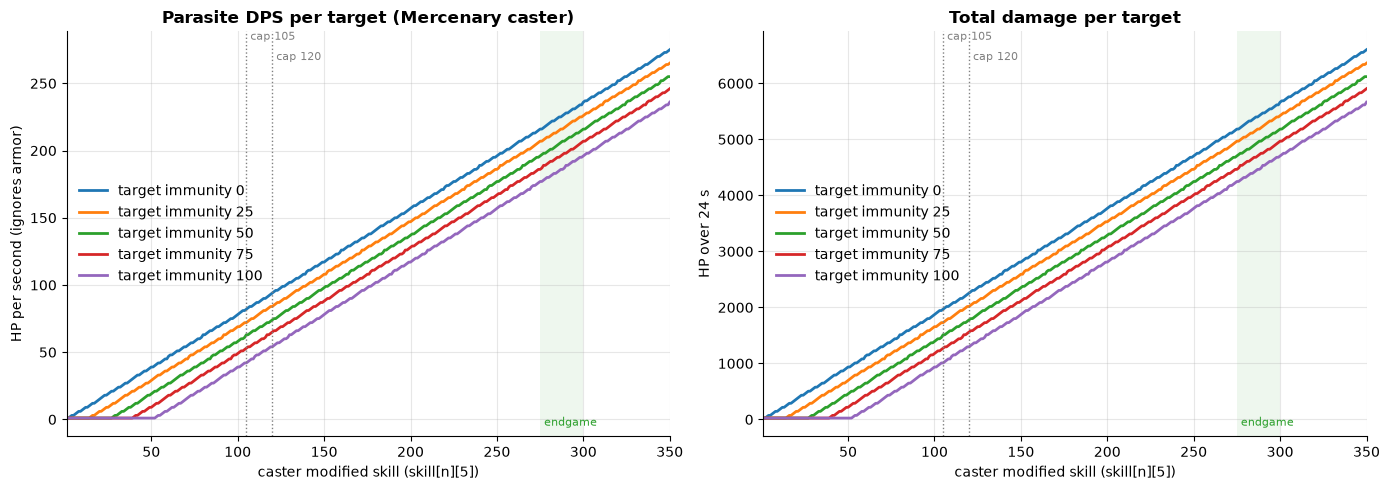

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for immun in mm.IMMUNITY_SWEEP:
    ax.plot(P, parasite_tick(P, immun), label=f"target immunity {immun}")
mm.skill_axis(ax, "HP per second (ignores armor)", "Parasite DPS per target (Mercenary caster)")
mm.mark_caps(ax)
ax.legend()

ax = axes[1]
for immun in mm.IMMUNITY_SWEEP:
    ax.plot(P, parasite_total(P, immun), label=f"target immunity {immun}")
mm.skill_axis(ax, "HP over 24 s", "Total damage per target")
mm.mark_caps(ax)
ax.legend()
plt.tight_layout()

Immunity subtracts a flat $I/2$ from skill before the ×¾ conversion. Each immunity step in the
sweep (25 points) therefore removes about 12.5 × ¾ × 1.05 ≈ 9.8 HP/s, or ~236 HP over the full
duration. Against immunity 100, Parasite does nothing useful until the caster's skill passes 50.

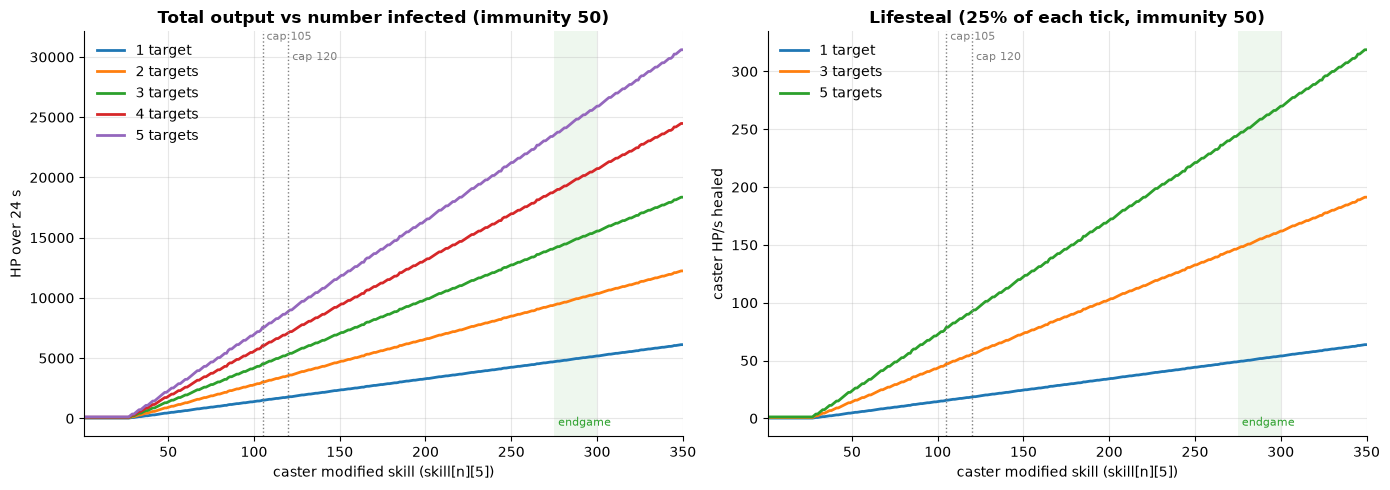

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for n in range(1, 6):
    ax.plot(P, n * parasite_total(P, immun=50), label=f"{n} target{'s' if n > 1 else ''}")
mm.skill_axis(ax, "HP over 24 s", "Total output vs number infected (immunity 50)")
mm.mark_caps(ax)
ax.legend()

ax = axes[1]
for n in (1, 3, 5):
    ax.plot(P, parasite_heal_total(P, immun=50, targets=n) / DURATION_S, label=f"{n} target{'s' if n > 1 else ''}")
mm.skill_axis(ax, "caster HP/s healed", "Lifesteal (25% of each tick, immunity 50)")
mm.mark_caps(ax)
ax.legend()
plt.tight_layout()

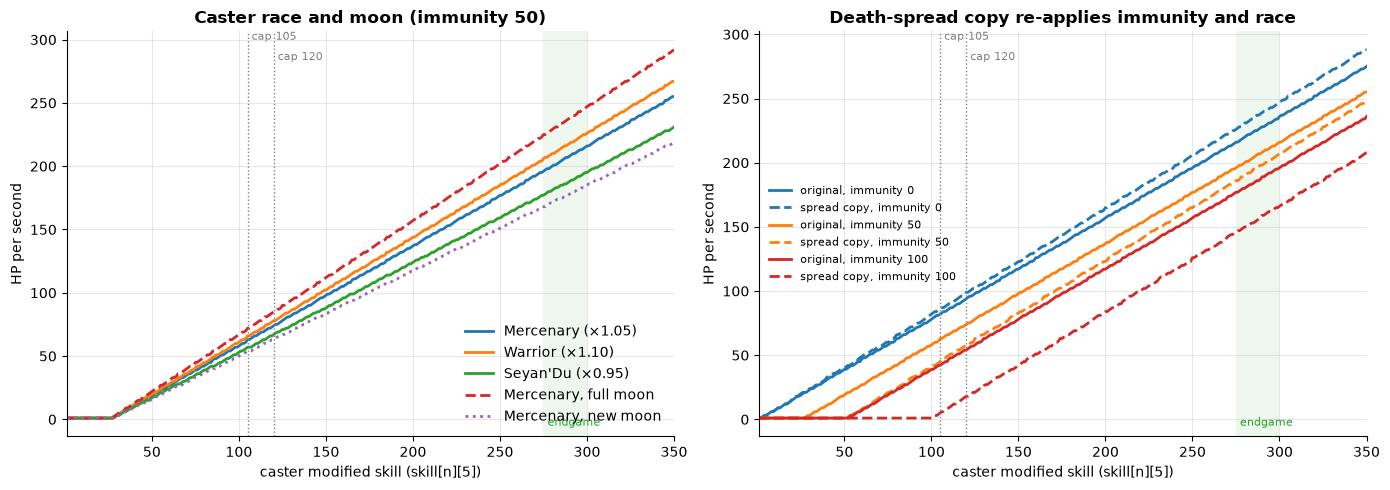

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Race comparison.
ax = axes[0]
for race in ("Mercenary", "Warrior", "Seyan'Du"):
    ax.plot(P, parasite_tick(P, 50, race), label=f"{race} (×{mm.RACE_MOD[race]:.2f})")
ax.plot(P, mm.dot_tick(mm.spell_power(P, 50, "Mercenary", moon="full")), ls="--", label="Mercenary, full moon")
ax.plot(P, mm.dot_tick(mm.spell_power(P, 50, "Mercenary", moon="new")), ls=":", label="Mercenary, new moon")
mm.skill_axis(ax, "HP per second", "Caster race and moon (immunity 50)")
mm.mark_caps(ax)
ax.legend()

# Death spread: original vs 8 s copy, both hosts with the same immunity.
ax = axes[1]
for immun, color in zip((0, 50, 100), ("tab:blue", "tab:orange", "tab:red")):
    stored = parasite_power(P, immun)
    ax.plot(P, mm.dot_tick(stored), color=color, label=f"original, immunity {immun}")
    ax.plot(P, mm.dot_tick(spread_power(stored, immun)), color=color, ls="--", label=f"spread copy, immunity {immun}")
mm.skill_axis(ax, "HP per second", "Death-spread copy re-applies immunity and race")
mm.mark_caps(ax)
ax.legend(fontsize=8)
plt.tight_layout()

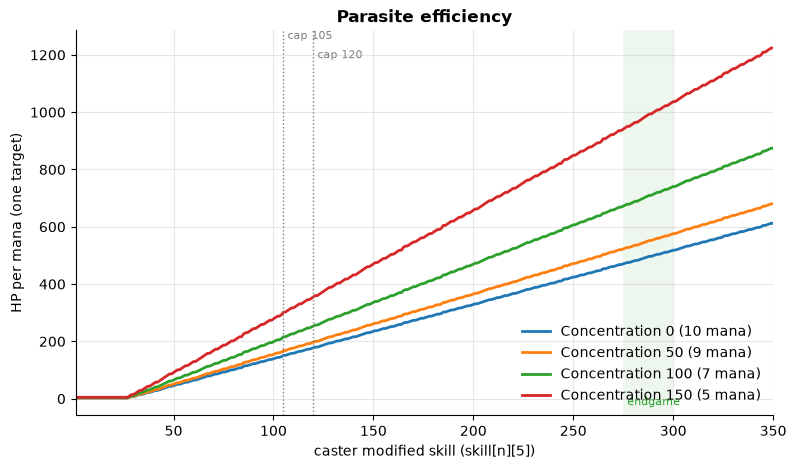

In [7]:
# Damage per mana at different Concentration values (single target, immunity 50).
fig, ax = plt.subplots()
for concen in (0, 50, 100, 150):
    cost = mm.spell_cost(10, concen)
    ax.plot(P, parasite_total(P, 50) / cost, label=f"Concentration {concen} ({cost} mana)")
mm.skill_axis(ax, "HP per mana (one target)", "Parasite efficiency")
mm.mark_caps(ax)
ax.legend()

# Observations

- At skill 120 against immunity 50, one 10-mana cast deals
  ~1780 HP (74 HP/s) to the main target over 24 s, with no landing roll and no armor. Up to four more
  enemies around the caster take the same amount. No other Mercenary or Harakim spell comes close
  per point of mana. The 24 s duration is the only brake.
- Secondary targets are the caster's cross neighbours, not
  the target's. A ranged cast at a far enemy still infects whoever is meleeing the caster.
- With five infected enemies at skill 120 and immunity 50, the
  caster heals ~92 HP/s, until the max-HP cap. Lifesteal also ignores the host's remaining HP. The
  caster is healed `tick/4` even if the host had only 1 HP left.
- The copy's power is
  `race(immun(p′, I_new))`. Immunity is subtracted twice and the race multiplier is applied
  twice. For a Mercenary this compounds to ×1.1025; for a Seyan'Du it compounds to ×0.9025.
  Against high-immunity targets the spread copy is much weaker than intended, e.g. 67 vs 84 power
  at skill 100 and immunity 40. The fix is to bypass `spell_immunity`/`spell_race_mod` when the
  power was already computed. One way is a `raw_power` flag on `apply_parasitic_dot`.
- The tick is linear in $p'$ up to skill 200. Only immunity mitigates it.